# Termómetro Digital — Análisis estadístico y pronóstico SARIMA

**Proyecto:** PIC16F887 + DHT11 + RTC + microSD  
**Entrada principal:** `sdcard.mmc`   
**Salida:** histórico en DataFrame, resumen estadístico con `pandas.describe()`, pronóstico de 6 pasos con `pmdarima`, gráficas con Matplotlib y CSV.

> **Objetivo:** usar Python como punto de referencia para validar el resumen estadístico y el pronóstico que realiza el microcontrolador.


In [2]:
# ============================================================
# 1. LIBRERÍAS
# ============================================================

from pathlib import Path
import math
import sys
import subprocess

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    import pmdarima as pm
    from pmdarima import auto_arima
except ImportError as exc:
    raise ImportError(
        
    ) from exc

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("pmdarima:", pm.__version__)
print("Python:", sys.version.split()[0])

pandas: 3.0.6
numpy: 2.5.3
pmdarima: 2.1.1
Python: 3.14.5


## 2. Configuración de entrada

La ruta corresponde a la ubicación:

`C:\Users\LENOVO\Documents\PICS\sdcard.mmc`


In [3]:
# ============================================================
# 2. CONFIGURACIÓN
# ============================================================

BLOCK_SIZE = 512
META_BLOCK = 99
DATA_START = 100

SD_IMAGE = Path(
    r"C:\Users\LENOVO\Documents\PICS\sdcard.mmc"
)

CSV_OUTPUT = SD_IMAGE.parent / "historico_termometro.csv"
FORECAST_OUTPUT = SD_IMAGE.parent / "pronostico_6_pasos.csv"

print("Archivo SD:")
print(SD_IMAGE)
print()
print("¿Existe?", SD_IMAGE.exists())

if SD_IMAGE.exists():
    print("Tamaño:", SD_IMAGE.stat().st_size, "bytes")

Archivo SD:
C:\Users\LENOVO\Documents\PICS\sdcard.mmc

¿Existe? True
Tamaño: 82944 bytes


In [5]:
# ============================================================
# 3. LECTURA DE BLOQUES DE 512 BYTES
# ============================================================

def read_block(file, block_number, size=BLOCK_SIZE):
    file.seek(block_number * BLOCK_SIZE)
    data = file.read(size)

    if len(data) != size:
        raise EOFError(
            f"No se pudo leer completo el bloque {block_number}."
        )

    return data

In [6]:
# ============================================================
# 4. METADATOS
# ============================================================

def read_metadata(path):
    with path.open("rb") as file:
        block = read_block(file, META_BLOCK)

    # Formato del firmware:
    # byte 0 = 'T'
    # byte 1 = 'M'
    # byte 2 = versión
    # bytes 4-5 = cantidad de registros

    if block[0:3] != b"TM\x01":
        raise ValueError(
            "La firma TM01 no coincide. "
            "Revisa que sea el sdcard.mmc del proyecto."
        )

    count = int.from_bytes(
        block[4:6],
        byteorder="little"
    )

    return count


total_registros = read_metadata(SD_IMAGE)

print("Registros almacenados:", total_registros)

Registros almacenados: 62


In [7]:
# ============================================================
# 5. DECODIFICAR UN REGISTRO
# ============================================================

def parse_record(block):
    # byte 0 = A5
    # byte 1 = versión
    # bytes 2-3 = número
    # byte 4 = año YY
    # byte 5 = mes
    # byte 6 = día
    # byte 7 = hora
    # byte 8 = minuto
    # byte 9 = segundo
    # byte 10 = temperatura
    # byte 11 = humedad

    if block[0] != 0xA5 or block[1] != 0x01:
        return None

    return {
        "numero": int.from_bytes(block[2:4], "little"),
        "anio": block[4],
        "mes": block[5],
        "dia": block[6],
        "hora": block[7],
        "minuto": block[8],
        "segundo": block[9],
        "temperatura": block[10],
        "humedad": block[11],
    }

In [8]:
# ============================================================
# 6. CARGAR TODO EL HISTÓRICO EN PANDAS
# ============================================================

def read_records(path):
    total = read_metadata(path)
    rows = []

    with path.open("rb") as file:

        for i in range(total):

            block = read_block(
                file,
                DATA_START + i
            )

            record = parse_record(block)

            if record is not None:
                rows.append(record)

    df = pd.DataFrame(rows)

    if df.empty:
        return total, df

    # Año almacenado como YY
    df["anio"] = 2000 + df["anio"].astype(int)

    df["fecha_hora"] = pd.to_datetime(
        {
            "year": df["anio"],
            "month": df["mes"].astype(int),
            "day": df["dia"].astype(int),
            "hour": df["hora"].astype(int),
            "minute": df["minuto"].astype(int),
            "second": df["segundo"].astype(int),
        },
        errors="coerce"
    )

    df = (
        df
        .sort_values("numero")
        .reset_index(drop=True)
    )

    # Asegurar tipos numéricos
    df["temperatura"] = pd.to_numeric(
        df["temperatura"],
        errors="coerce"
    )

    df["humedad"] = pd.to_numeric(
        df["humedad"],
        errors="coerce"
    )

    df = df.dropna(
        subset=[
            "fecha_hora",
            "temperatura",
            "humedad"
        ]
    ).reset_index(drop=True)

    return total, df


total, df = read_records(SD_IMAGE)

print("Registros indicados por la SD:", total)
print("Registros válidos encontrados:", len(df))

df

Registros indicados por la SD: 62
Registros válidos encontrados: 62


,numero,anio,mes,dia,hora,minuto,segundo,temperatura,humedad,fecha_hora
0,0,2026,10,3,12,0,10,27,76,2026-10-03 12:00:10
1,1,2026,10,3,12,0,20,27,76,2026-10-03 12:00:20
2,2,2026,10,3,12,0,30,27,76,2026-10-03 12:00:30
3,3,2026,10,3,12,0,40,27,76,2026-10-03 12:00:40
4,4,2026,10,3,12,0,50,27,76,2026-10-03 12:00:50
...,...,...,...,...,...,...,...,...,...,...
57,57,2026,10,7,9,15,39,32,76,2026-10-07 09:15:39
58,58,2026,10,7,9,15,49,32,76,2026-10-07 09:15:49
59,59,2026,10,7,9,15,59,32,76,2026-10-07 09:15:59
60,60,2026,10,7,9,16,9,32,76,2026-10-07 09:16:09


## 3. Histórico

Esta tabla contiene los datos reales que el PIC escribió en la imagen de la SD.

In [9]:
# ============================================================
# 7. TABLA DE HISTÓRICO
# ============================================================

if df.empty:
    print("No hay registros válidos.")
else:
    columnas = [
        "numero",
        "fecha_hora",
        "temperatura",
        "humedad"
    ]

    display(df[columnas])

,numero,fecha_hora,temperatura,humedad
0,0,2026-10-03 12:00:10,27,76
1,1,2026-10-03 12:00:20,27,76
2,2,2026-10-03 12:00:30,27,76
3,3,2026-10-03 12:00:40,27,76
4,4,2026-10-03 12:00:50,27,76
...,...,...,...,...
57,57,2026-10-07 09:15:39,32,76
58,58,2026-10-07 09:15:49,32,76
59,59,2026-10-07 09:15:59,32,76
60,60,2026-10-07 09:16:09,32,76


## 4. Resumen estadístico con `describe()`

El profesor recomendó usar `pandas.describe()` para reducir código. Esta función entrega directamente:

**Count, Mean, Std, Min, 25%, 50%, 75%, Max**

sobre las columnas numéricas seleccionadas.

> Nota metodológica: `describe()` utiliza las convenciones estadísticas de Pandas/NumPy. Por eso `Std` y algunos percentiles pueden no coincidir exactamente con la implementación entera que usa el PIC. Para el notebook de referencia esto es correcto y, además, podemos mostrar ambas perspectivas.

In [10]:
# ============================================================
# 8. ESTADÍSTICAS CON PANDAS.DESCRIBE()
# ============================================================

if df.empty:
    print("No hay datos.")
else:

    estadisticas = (
        df[
            [
                "temperatura",
                "humedad"
            ]
        ]
        .describe()
        .T
    )

    display(estadisticas)

,count,mean,std,min,25%,50%,75%,max
temperatura,62.0,31.661290,2.095613,27.0,32.0,33.0,33.0,33.0
humedad,62.0,79.177419,2.972685,76.0,76.0,82.0,82.0,82.0


In [11]:
# ============================================================
# 9. TABLA DE ESTADÍSTICAS FORMATEADA
# ============================================================

if not df.empty:

    estadisticas_presentacion = (
        df[
            [
                "temperatura",
                "humedad"
            ]
        ]
        .describe()
        .T
        .rename(
            columns={
                "count": "Count",
                "mean": "Mean",
                "std": "Std",
                "min": "Min",
                "25%": "25%",
                "50%": "50%",
                "75%": "75%",
                "max": "Max"
            }
        )
    )

    display(
        estadisticas_presentacion.round(2)
    )

,Count,Mean,Std,Min,25%,50%,75%,Max
temperatura,62.0,31.66,2.10,27.0,32.0,33.0,33.0,33.0
humedad,62.0,79.18,2.97,76.0,76.0,82.0,82.0,82.0


## 5. Referencia del modelo SARIMA aportada para entrenamiento

La ecuación que se agregó como referencia contiene términos autorregresivos no estacionales de rezagos 1 y 2, un término estacional de rezago 12 y una parte MA de rezago 1:

$$
x_t =
\\phi_1 x_{t-1}
+ \\phi_2 x_{t-2}
+ \\Phi_1 x_{t-12}
+ \\phi_1\\Phi_1 x_{t-13}
- \\phi_2\\Phi_1 x_{t-14}
+ z_t
- \\theta_1 z_{t-1}
$$

En la captura entregada aparecen los parámetros:

| Parámetro | Valor mostrado |
|---|---:|
| $\\phi_1$ | 1.2933 |
| $\\phi_2$ | -0.3157 |
| $\\theta_1$ | -0.9101 |
| $\\sigma^2$ | 0.3117 |
| AIC | 3070.48 |

La captura no muestra el valor numérico de $\\Phi_1$, por lo que **no se inventa ni se fija manualmente** en este notebook.

Para el proyecto, `pmdarima.auto_arima()` se utiliza para estimar automáticamente un modelo de la familia ARIMA/SARIMA a partir de los datos disponibles. El parámetro estacional `m=12` conserva la idea de un rezago estacional de 12 pasos de la ecuación de referencia.

**Interpretación para este proyecto:** en la versión definitiva, cada paso representa una hora, por lo que `m=12` corresponde a una posible estacionalidad de 12 horas. El modelo se valida con los datos reales disponibles y no se obliga a usar literalmente los coeficientes de la publicación de referencia.

In [12]:
# ============================================================
# 10. INTERVALO TEMPORAL OBSERVADO
# ============================================================

def infer_step_hours(df):
    if len(df) < 2:
        return None

    deltas = (
        df["fecha_hora"]
        .sort_values()
        .diff()
        .dropna()
        .dt.total_seconds()
        / 3600
    )

    if deltas.empty:
        return None

    return float(deltas.median())


step_hours = infer_step_hours(df)

if step_hours is None:
    print("No hay suficientes registros para inferir el intervalo.")
else:
    print(
        f"Intervalo mediano entre registros: "
        f"{step_hours:.6f} horas"
    )

    if abs(step_hours - 1.0) < 0.1:
        print("Interpretación: 1 registro ≈ 1 hora.")
    else:
        print(
            "Interpretación: los datos no están espaciados a 1 hora; "
            "el pronóstico se mostrará como pasos de serie."
        )

Intervalo mediano entre registros: 0.002778 horas
Interpretación: los datos no están espaciados a 1 hora; el pronóstico se mostrará como pasos de serie.


## 6. Pronóstico con `pmdarima`

`pmdarima` incluye una implementación de `auto_arima`, equivalente en objetivo a la selección automática de modelos ARIMA. Para la serie del proyecto se intenta primero un modelo estacional con `m=12`, coherente con la ecuación de referencia.

Para que la notebook sea robusta con el historial corto de una prueba, si no hay suficientes observaciones o el ajuste estacional falla, se intenta un ARIMA no estacional. Así no se rompe el notebook mientras se siguen recolectando datos.

In [14]:
# ============================================================
# 11. AJUSTE ROBUSTO CON PMDARIMA
# ============================================================

def fit_auto_arima(series, seasonal_period=12):
    y = pd.Series(series).dropna().astype(float).reset_index(drop=True)

    if len(y) < 6:
        raise ValueError(
            "Se necesitan al menos 6 observaciones para intentar "
            "el pronóstico."
        )

    # Modelo estacional cuando existe suficiente historial.
    if len(y) >= 24:
        try:
            model = auto_arima(
                y,
                seasonal=True,
                m=seasonal_period,
                start_p=0,
                start_q=0,
                max_p=2,
                max_q=2,
                start_P=0,
                start_Q=0,
                max_P=1,
                max_Q=1,
                stepwise=True,
                suppress_warnings=True,
                error_action="ignore",
                trace=False,
                information_criterion="aic",
            )

            return model, "SARIMA estacional (m=12)"

        except Exception as error:
            print(
                "Aviso: el ajuste estacional no fue posible.",
                "Se usará ARIMA no estacional.",
                "\nDetalle:",
                error
            )

    # Fallback para históricos cortos.
    model = auto_arima(
        y,
        seasonal=False,
        start_p=0,
        start_q=0,
        max_p=2,
        max_q=2,
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore",
        trace=False,
        information_criterion="aic",
    )

    return model, "ARIMA no estacional"


def forecast_series(series, n_steps=6):
    model, model_type = fit_auto_arima(
        series,
        seasonal_period=12
    )

    prediction = model.predict(
        n_periods=n_steps
    )

    return model, model_type, np.asarray(prediction, dtype=float)

In [15]:
# ============================================================
# 12. PRONÓSTICO DE TEMPERATURA Y HUMEDAD
# ============================================================

if len(df) < 6:

    print(
        "Todavía no hay suficientes registros. "
        "Se necesitan al menos 6."
    )

    temp_model = None
    hum_model = None
    forecast = pd.DataFrame()

else:

    # Temperatura
    temp_model, temp_model_type, temp_pred = forecast_series(
        df["temperatura"],
        n_steps=6
    )

    # Humedad
    hum_model, hum_model_type, hum_pred = forecast_series(
        df["humedad"],
        n_steps=6
    )

    # Limitar a rangos razonables del DHT11
    temp_pred = np.clip(
        temp_pred,
        0,
        50
    )

    hum_pred = np.clip(
        hum_pred,
        0,
        100
    )

    # Construir fechas futuras
    if step_hours is not None and step_hours > 0:
        step_delta = pd.to_timedelta(
            step_hours,
            unit="h"
        )
    else:
        # Fallback para datos sin timestamp utilizable.
        step_delta = pd.Timedelta(hours=1)

    future_times = [
        df["fecha_hora"].iloc[-1]
        + step_delta * i
        for i in range(1, 7)
    ]

    forecast = pd.DataFrame(
        {
            "paso": range(1, 7),
            "fecha_hora": future_times,
            "temperatura_predicha": temp_pred,
            "humedad_predicha": hum_pred,
        }
    )

    display(forecast)

    print("Modelo temperatura:", temp_model_type)
    print("Modelo humedad:", hum_model_type)

,paso,fecha_hora,temperatura_predicha,humedad_predicha
0,1,2026-10-07 09:16:29,31.919695,76.0
1,2,2026-10-07 09:16:39,31.846980,76.0
2,3,2026-10-07 09:16:49,31.781137,76.0
3,4,2026-10-07 09:16:59,31.721518,76.0
4,5,2026-10-07 09:17:09,31.667534,76.0
5,6,2026-10-07 09:17:19,31.618652,76.0


Modelo temperatura: SARIMA estacional (m=12)
Modelo humedad: SARIMA estacional (m=12)


## 7. Inspección del modelo seleccionado

Además de producir las predicciones, mostramos el orden elegido por `auto_arima`, el AIC y otros datos del modelo.

In [16]:
# ============================================================
# 13. INFORMACIÓN DE LOS MODELOS
# ============================================================

if temp_model is not None:

    print("=== TEMPERATURA ===")
    print("Modelo:", temp_model_type)
    print("Orden:", temp_model.order)
    print("Orden estacional:", temp_model.seasonal_order)
    print("AIC:", temp_model.aic())

    print()

    print("=== HUMEDAD ===")
    print("Modelo:", hum_model_type)
    print("Orden:", hum_model.order)
    print("Orden estacional:", hum_model.seasonal_order)
    print("AIC:", hum_model.aic())

=== TEMPERATURA ===
Modelo: SARIMA estacional (m=12)
Orden: (1, 0, 0)
Orden estacional: (0, 0, 0, 12)
AIC: 178.98798279692767

=== HUMEDAD ===
Modelo: SARIMA estacional (m=12)
Orden: (0, 1, 0)
Orden estacional: (0, 0, 0, 12)
AIC: 162.9805986748354


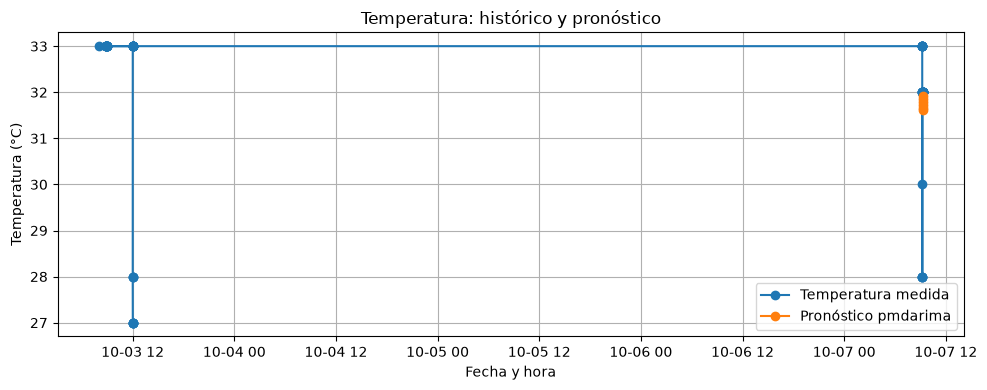

In [17]:
# ============================================================
# 14. GRÁFICA DE TEMPERATURA + PRONÓSTICO
# ============================================================

if df.empty or forecast.empty:

    print("No hay datos suficientes para graficar.")

else:

    plt.figure(figsize=(10, 4))

    plt.plot(
        df["fecha_hora"],
        df["temperatura"],
        marker="o",
        label="Temperatura medida"
    )

    plt.plot(
        forecast["fecha_hora"],
        forecast["temperatura_predicha"],
        marker="o",
        label="Pronóstico pmdarima"
    )

    plt.xlabel("Fecha y hora")
    plt.ylabel("Temperatura (°C)")
    plt.title("Temperatura: histórico y pronóstico")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

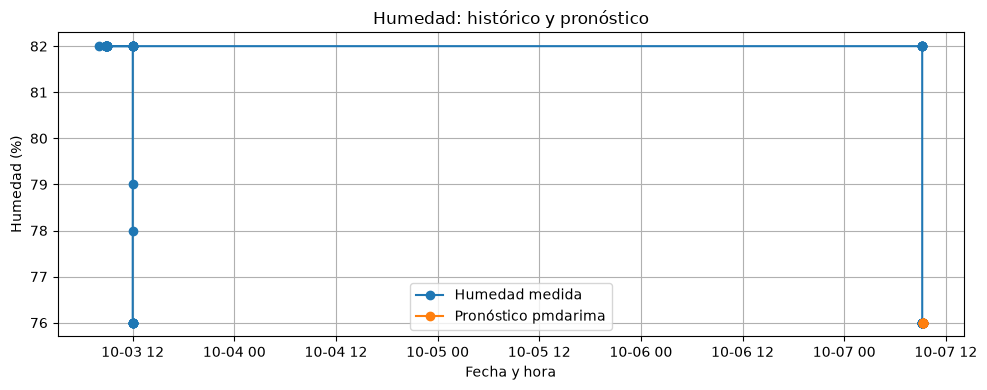

In [18]:
# ============================================================
# 15. GRÁFICA DE HUMEDAD + PRONÓSTICO
# ============================================================

if df.empty or forecast.empty:

    print("No hay datos suficientes para graficar.")

else:

    plt.figure(figsize=(10, 4))

    plt.plot(
        df["fecha_hora"],
        df["humedad"],
        marker="o",
        label="Humedad medida"
    )

    plt.plot(
        forecast["fecha_hora"],
        forecast["humedad_predicha"],
        marker="o",
        label="Pronóstico pmdarima"
    )

    plt.xlabel("Fecha y hora")
    plt.ylabel("Humedad (%)")
    plt.title("Humedad: histórico y pronóstico")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 8. Exportar el histórico y el pronóstico a CSV

El notebook genera dos archivos:

- `historico_termometro.csv`
- `pronostico_6_pasos.csv`

In [19]:
# ============================================================
# 16. EXPORTAR CSV
# ============================================================

if not df.empty:

    historico_export = df[
        [
            "numero",
            "fecha_hora",
            "temperatura",
            "humedad"
        ]
    ].copy()

    historico_export.to_csv(
        CSV_OUTPUT,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "Histórico exportado:",
        CSV_OUTPUT
    )


if not forecast.empty:

    forecast.to_csv(
        FORECAST_OUTPUT,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "Pronóstico exportado:",
        FORECAST_OUTPUT
    )

Histórico exportado: C:\Users\LENOVO\Documents\PICS\historico_termometro.csv
Pronóstico exportado: C:\Users\LENOVO\Documents\PICS\pronostico_6_pasos.csv


## 9. Comparación rápida con el pronóstico simple del PIC

El firmware validado utiliza una extrapolación basada en la diferencia entre las dos últimas mediciones. Dejamos esa referencia para comparar contra el modelo SARIMA/ARIMA de Python.

Esto es útil para el informe porque muestra que Python no solo produce un resultado, sino que permite contrastar el método sencillo del microcontrolador con un modelo de series de tiempo.

In [ ]:
# ============================================================
# 17. PRONÓSTICO SIMPLE DEL PIC PARA COMPARAR
# ============================================================

def pic_reference_forecast(df, n_steps=6):
    if len(df) < 2:
        return pd.DataFrame()

    prev_t = float(df.iloc[-2]["temperatura"])
    last_t = float(df.iloc[-1]["temperatura"])

    prev_h = float(df.iloc[-2]["humedad"])
    last_h = float(df.iloc[-1]["humedad"])

    delta_t = last_t - prev_t
    delta_h = last_h - prev_h

    rows = []

    for step in range(1, n_steps + 1):

        t = np.clip(
            last_t + delta_t * step,
            0,
            50
        )

        h = np.clip(
            last_h + delta_h * step,
            0,
            100
        )

        rows.append(
            {
                "paso": step,
                "temp_pic": t,
                "hum_pic": h
            }
        )

    return pd.DataFrame(rows)


if len(df) >= 2:

    pic_forecast = pic_reference_forecast(
        df,
        n_steps=6
    )

    comparacion = forecast.merge(
        pic_forecast,
        on="paso",
        how="left"
    )

    display(comparacion)
else:
    print("No hay dos registros para calcular la referencia del PIC.")

,paso,fecha_hora,temperatura_predicha,humedad_predicha,temp_pic,hum_pic
0,1,2026-10-07 09:16:29,31.919695,76.0,32.0,76.0
1,2,2026-10-07 09:16:39,31.846980,76.0,32.0,76.0
2,3,2026-10-07 09:16:49,31.781137,76.0,32.0,76.0
3,4,2026-10-07 09:16:59,31.721518,76.0,32.0,76.0
4,5,2026-10-07 09:17:09,31.667534,76.0,32.0,76.0
5,6,2026-10-07 09:17:19,31.618652,76.0,32.0,76.0


## 10. Resultado final del informe

Al ejecutar todas las celdas, la evidencia disponible es:

**Entrada**
- registros reales escritos por el PIC en `sdcard.mmc`.

**Procesamiento**
- DataFrame con fecha, hora, temperatura y humedad.
- resumen estadístico mediante `pandas.describe()`.
- modelo ARIMA/SARIMA seleccionado mediante `pmdarima.auto_arima()`.
- pronóstico de seis pasos.
- comparación opcional con el pronóstico de referencia del PIC.

**Salidas**
- histórico `historico_termometro.csv`.
- pronóstico `pronostico_6_pasos.csv`.
- dos gráficas independientes: temperatura y humedad.

